## Measuring Performance of GPT model

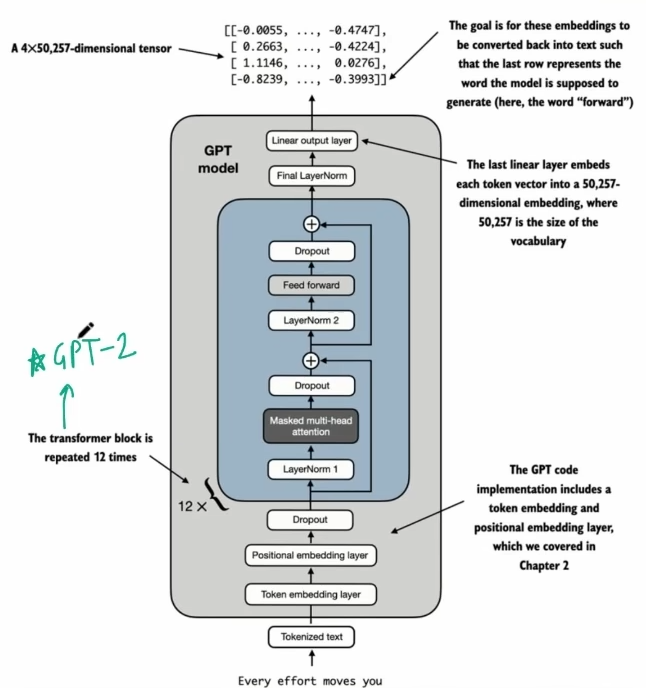

In [1]:
from IPython.display import Image
Image("images/stage1_6_GPT2_model/GPT2_model.png", width=600)

In [2]:
import torch
import torch.nn as nn
torch.set_printoptions(sci_mode=False)



In [3]:
# GPT_CONFIG_124M = {
#     "vocab_size": 50257,     # Vocabulary size of the model
#     "context_length": 1024,  # Maximum context length for the model
#     "emb_dim": 768,          # Embedding dimension of the model
#     "n_heads": 12,           # Number of attention heads in the model
#     "n_layers": 12,          # Number of transformer layers in the model
#     "drop_rate": 0.1,        # Dropout rate for regularization
#     "qkv_bias": True         # Whether to include bias terms in the query, key, and value projections
# }

### The Building Blocks: Layer Normalization, GELU and Feed-forward network

In [4]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        
        self.head_dim = d_out // num_heads

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

        self.out_proj = nn.Linear(d_out, d_out)

        self.dropout = nn.Dropout(dropout)

        self.register_buffer("mask", torch.triu(torch.ones(context_length, context_length), diagonal=1))


    def forward(self, x):
        b, num_tokens, d_in = x.shape

        keys = self.W_key(x)  # (b, num_tokens, d_out)
        queries = self.W_query(x)  # (b, num_tokens, d_out)
        values = self.W_value(x)  # (b, num_tokens, d_out)

        # we implicitly split the matrix by adding a new dimension for the heads "num_heads"
        # unroll last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)

        # transpose to get dimensions: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        # we wan th grouping to be the heads, so we swap the num_heads and num_tokens dimensions not on tokens

        keys = keys.transpose(1, 2)  # (b, num_heads, num_tokens, head_dim)
        queries = queries.transpose(1, 2)  # (b, num_heads, num_tokens, head_dim)
        values = values.transpose(1, 2)  # (b, num_heads, num_tokens, head_dim)

        # compute scaled dot product attention (aka slef attention) with a causal mask
        # we compute the attention scores by taking the dot product of the queries and keys
        attn_scores = queries @ keys.transpose(2, 3)  

        # original mask truncated to the number of tokens in the input and converted to boolean
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        # use the mask to fill the attention scores
        attn_scores.masked_fill_(mask_bool, -torch.inf)

        # calculate the attention weights by applying softmax to the attention scores
        # # keys.shape[-1] is the head_dim, we scale the attention scores by the square root of the head dimension 
        # to prevent them from getting too large
        attn_weights = torch.softmax(attn_scores/keys.shape[-1]**0.5, dim=-1) 
        attn_weights = self.dropout(attn_weights)

        # calculate context vector as the weighted sum of the values, using the attention weights
        # transpose to keep num_heads & head_dim together for the output
        context_vec = (attn_weights @ values).transpose(1,2)

        # combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)

        return context_vec




In [5]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True) # calculate row-wise mean
        var = x.var(dim=-1, keepdim=True, unbiased=False) # calculate row-wise variance
        x_norm = (x - mean) / torch.sqrt(var + self.eps) # eps is added to avoid division by zero
        return self.scale * x_norm + self.shift


class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) * 
            (x + 0.044715 * torch.pow(x, 3))
            ))
    

class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),  ## Expansion
            GELU(), ## Activation
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"])   ## Contraction
        )

    def forward(self, x):
        return self.layers(x)
    

### Let's Build entire Transformer Block

- Step 1: Shortcut connection for attention block

- Step 2: Shortcut connection for feed forward block

- Step 3: Add the original input back

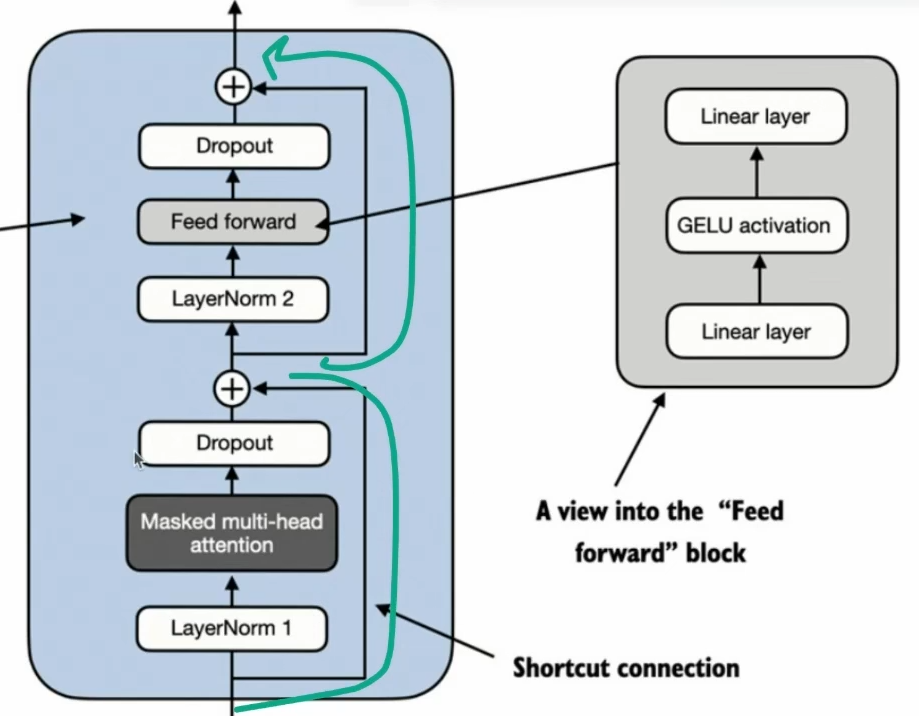

In [6]:
Image("images/stage_1_4_shortcut_conn/shorcut_in_transformer.png", width=700)

In [7]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
                    d_in=cfg["emb_dim"], 
                    d_out=cfg["emb_dim"], 
                    context_length=cfg["context_length"], 
                    num_heads=cfg["n_heads"], 
                    dropout=cfg["drop_rate"], 
                    qkv_bias=cfg["qkv_bias"])

        self.ff = FeedForward(cfg)

        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])

        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])
        


    def forward(self, x):
        # first part: layer_norm -> attention -> dropout -> add shortcut

        # shorcut connection for transformer block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)  # shape = (batch_size, num_tokens, emb_dim)
        x = self.drop_shortcut(x)
        x = x + shortcut  # shortcut connection: Add the original input to the output of the attention layer

        # second part: layer_norm -> feedforward -> dropout -> add shortcut
        
        # shorcut connection for transformer block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut  # shortcut connection: Add the original input to the output of the attention layer

        return x



- Layer normalization is applied before each of 2 components, and dropout is applied after them to regularize the model and reduce overfitting.

- This is also known as Pre-LayerNorm

- Older architectures, such as original transformer model, appied layer normalizaion after the self-attention and feed-forward network instead, known as POST-LAYERNORM, which often leads to worse training dynamics.

- The class also implements the forward pass, where each component is followed by a shortcut connection that adds the input of the block to its output. This critical feature helps gradient flow through the network during training and improves the learnig of deep models.

## GPT-2 model

In [8]:
class GPTmodel(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.tok_emb = nn.Embedding(config["vocab_size"], config["emb_dim"])
        self.pos_emb = nn.Embedding(config["context_length"], config["emb_dim"])
        self.drop_emb = nn.Dropout(config["drop_rate"])

        # 12 transformer blocks, each with 12 attention heads and 768 embedding dimensions
        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(config) for _ in range(config["n_layers"])])

        # ApplyLayerNorm
        self.final_norm = LayerNorm(config["emb_dim"])
        self.out_head = nn.Linear(config["emb_dim"], config["vocab_size"], bias=False)


    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        # step1: Get token embeddings
        tok_emb = self.tok_emb(in_idx)  # Token embeddings

        # step2: Get positional embeddings
        pos_emb = self.pos_emb(torch.arange(seq_len, device=in_idx.device))  # Positional embeddings
        x = tok_emb + pos_emb  # Combine token and positional embeddings

        # step3: Apply dropout to the combined embeddings
        x = self.drop_emb(x)

        # step4: Pass through transformer blocks
        x = self.trf_blocks(x)

        # step5: Apply final layer normalization
        x = self.final_norm(x)

        # step6: Compute logits for the vocabulary
        logits = self.out_head(x)
        return logits

<div class="alert alert-block alert-warning">

- The init constructor of this GPT model initializes the token and positional embedding layer using the configuration passed.

- These embedding layers are responsible for converting the input token indices into dense vectors and assing positional information


- Next, the init method creates a sequential stack of Transformer Block modules equal to the number of layers specified in config.

- Following the Transformer Block, a LayerNorm is applied, standardizing the output from the transformer block to stabilize learning.

- Finally a linear output head without bias is defined, which projects the transormer's output into the vocabulary space of the tokenizer to generate logits for each token in the vocabulary.

- The forward method takes the batch of input token indices, computes their embeddings, applies the positional embedding, passes the sequence through the transformer block, normalizes the final output, and then compues the logits , representing the next token's unnormalized probabilities. We will convert those logits into tokens and text outputs.

</div>

#### Let's instaniate the GPT model

In [9]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
    
    for _ in range(max_new_tokens):
        # crop idx to the last context_size tokens
        idx_cond = idx[:, -context_size:]

        # get logits for the next token
        with torch.no_grad():  # Disable gradient calculation for inference
            logits = model(idx_cond) ### batch, n_tokens, vocab_size

        # focus on the last time step
        # batch, n_tokens, vocab_size -> batch, vocab_size
        logits = logits[:, -1, :]

        # apply softmax to get probabilities
        # applied along the vocab dimension to get probabilities for each token in the vocabulary
        probs = torch.softmax(logits, dim=-1) 

        # get the idx of the token with the highest probability
        idx_next = torch.argmax(probs, dim=-1, keepdim=True) 

        # append sampled token to the sequence
        idx = torch.cat((idx, idx_next), dim=1)

    return idx

In [10]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,     # Vocabulary size of the model
    "context_length": 256,  # Maximum context length for the model
    "emb_dim": 768,          # Embedding dimension of the model
    "n_heads": 12,           # Number of attention heads in the model
    "n_layers": 12,          # Number of transformer layers in the model
    "drop_rate": 0.1,        # Dropout rate for regularization
    "qkv_bias": True         # Whether to include bias terms in the query, key, and value projections
}

In [11]:
import torch 
torch.manual_seed(123)  # For reproducibility
model = GPTmodel(GPT_CONFIG_124M)

model.eval()

GPTmodel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(256, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_value): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=76

#### We have reduced the context_length to only 256 tokens to reduce the computational resources requiremnets for training the model.

- Let's build 2 functions generate_text_simple to generate text.

- We will also define 2 other functions text_to_token_ids and token_ids_to_text for converting between token and text representations. 

In [12]:
import tiktoken

def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={"|<end_of_text>|"})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0)  # Add batch dimension
    return encoded_tensor

def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0)  # remove batch dimension
    return tokenizer.decode(flat.tolist())

start_context = "Every effort moves you"
tokenizer = tiktoken.get_encoding("gpt2")
token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(start_context, tokenizer),
    max_new_tokens=10,
    context_size=GPT_CONFIG_124M["context_length"]
)

print("output text: ", token_ids_to_text(token_ids, tokenizer))

output text:  Every effort moves you pundits sax Thailand licensedyson standing scram170rawn colossal


<div class="alert alert-block alert-warning">

- The reason why model is generating random text is because, we haven't trained the model yet

- How do we measure or capture what "good text" is, in numeric form, to track it during training ?

- We will introduce a metric, to calculate loss for the generated output that we can use

- We will use the same in finetuning LLMs to measure response quality.

</div>

## Calculate the text Generation loss: cross-entropy and perplexity

- We have input tensor containing the token IDs for 2 training examples

- Corresponding to nputs, we have outputs, shifted by 1 (which are basically desired token IDs )

In [13]:
inputs = torch.tensor([[16833, 3626, 6100],  # ["every", "effort", "moves"]
                        [40, 1107, 588]])    # ["I", "really", "like"]

targets = torch.tensor([[3626, 6100, 345],   # ["effort", "moves", "you"]
                        [1107, 588, 11311]]) # ["really", "like", "chocolate"]

- Feeding inputs to the model, we obtain logits vectors of the 2 input examples

- Each of the tokens is a 50,257 dimensional vector, corresponding to the size of vocabulary

- Applying the Softmax function, we can turn the logits tensor into tensor of same dimension

In [14]:
with torch.no_grad():
    logits = model(inputs)

probas = torch.softmax(logits, dim=1)  # probability of each token in vocabulary
print(probas.shape) # shape: (batch_size, num_tokens, vocabulary)

torch.Size([2, 3, 50257])


- We can apply argmax function to convert probabilities score

- The softmax function produced a 50257 dimensional vector for each token; the argmax function gives the max value for the vector; which is the predict token ID for the given token.

- Since, we have 2 batches with 3 tokens each, we obtain 2 by 3 predicted token IDs

In [15]:
token_ids = torch.argmax(probas, dim=-1, keepdim=True)

print("Token IDs: ", token_ids)



Token IDs:  tensor([[[28545],
         [45217],
         [16574]],

        [[44259],
         [48168],
         [50254]]])


- If we decode these tokens, we will find that these are quite different from the tokens we want the model to predict

- That's because the model is not trained yet

- To train the model, we need to know how far it is away from the correct predictions (target)

In [16]:
print("Target batch 1: ", token_ids_to_text(targets[0], tokenizer))

print("Output batch 1: ", token_ids_to_text(token_ids[0].flatten(), tokenizer))

Target batch 1:   effort moves you
Output batch 1:  Dailyselage travelling


## Cross-entropy loss

In [17]:
text_idx = 0
target_probas_1 = probas[text_idx, [0,1,2], targets[text_idx]]  # shape: (3,)
print("Target probabilities for batch 1: ", target_probas_1)

text_idx = 1
target_probas_2 = probas[text_idx, [0,1,2], targets[text_idx]]  # shape: (3,)
print("Target probabilities for batch 2: ", target_probas_2)

Target probabilities for batch 1:  tensor([0.3732, 0.2654, 0.2378])
Target probabilities for batch 2:  tensor([0.1447, 0.4406, 0.1287])


- We want to maximize the values, bringing them closer to a probability of 1

In [18]:
# compute log of all token probabilities

log_probas = torch.log(torch.cat((target_probas_1, target_probas_2)))  # shape: (6,)
print("Log probabilities: ", log_probas)

Log probabilities:  tensor([-0.9857, -1.3263, -1.4365, -1.9333, -0.8197, -2.0501])


In [19]:
# compute the average probabilities for the two batches

avg_log_probas = torch.mean(log_probas)  # shape: (1,)
print("Average log probabilities: ", avg_log_probas)



Average log probabilities:  tensor(-1.4253)


- The goal is to make thie average log probability values to be as large as possible by optimizing the model weights.

- Due to log, the largest possible vaue is 0, and we are currently away from 0

- In Deep Learning, instead of maximizing the average log-probability, it's standard conventionto minimize the negative average log likelihood, instead of maximizing the (average log prob) so that it approaches to 0. We would rather minimize the (negative average log)
so it approaches 0

- the value of negative -1.4253 i.e 1.4253 is also called the cross-entropy loss in deep learning



In [20]:
neg_avg_log_probas = avg_log_probas * -1
print("Negative average log probabilities: ", neg_avg_log_probas)

Negative average log probabilities:  tensor(1.4253)


In [21]:
# logits shape
print("Logits shape: ", logits.shape)  # shape: (batch_size, num_tokens, vocabulary)

# target shape
print("Targets shape: ", targets.shape)  # shape: (batch_size, num_tokens)

Logits shape:  torch.Size([2, 3, 50257])
Targets shape:  torch.Size([2, 3])


- We can implement all the above steps using the Pytor function as well

In [22]:
logits_flat = logits.flatten(0, 1)  # shape: (batch_size * num_tokens, vocabulary)
targets_flat = targets.flatten()  # shape: (batch_size * num_tokens)

print("Logits flat shape: ", logits_flat.shape)  # shape: (batch_size * num_tokens, vocabulary)
print("Targets flat shape: ", targets_flat.shape)  # shape: (batch_size * num_tokens)

Logits flat shape:  torch.Size([6, 50257])
Targets flat shape:  torch.Size([6])


In [23]:
loss = torch.nn.functional.cross_entropy(logits_flat, targets_flat)
print("Cross-entropy loss: ", loss)

Cross-entropy loss:  tensor(11.2027)


In [24]:
# perplexity
perplexity = torch.exp(loss)
print("Perplexity: ", perplexity)

Perplexity:  tensor(73324.8516)


## Calculating Training and Validation Set Losses

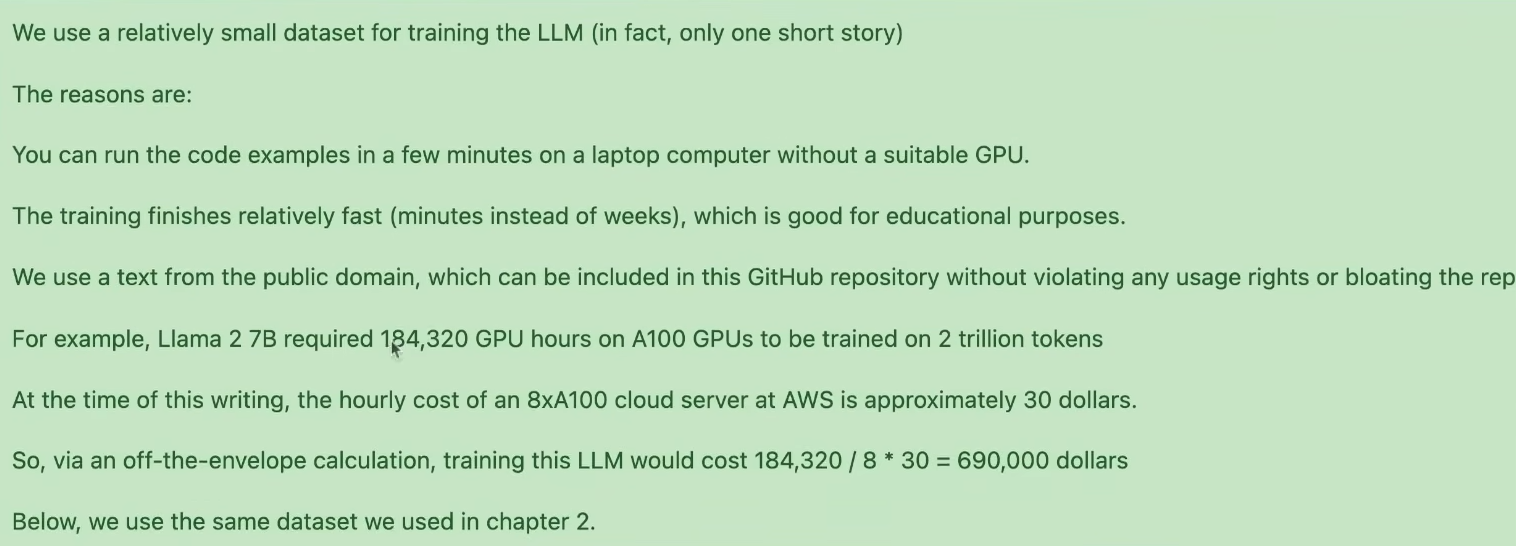

In [26]:

Image("images/stage2_2_LLM_Training_evaluation/task_description.png", width=700)

In [28]:
import os

In [29]:
file_path = "the-verdict.txt"

with open(file_path, 'r', encoding='utf-8') as file:
    text_data = file.read()

In [30]:
# quick check if data is loaded, by printing 100 words from the text data
print("First 100 words of the text data: ", ' '.join(text_data.split()[:100]))

First 100 words of the text data:  I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no great surprise to me to hear that, in the height of his glory, he had dropped his painting, married a rich widow, and established himself in a villa on the Riviera. (Though I rather thought it would have been Rome or Florence.) "The height of his glory"--that was what the women called it. I can hear Mrs. Gideon Thwing--his last Chicago sitter--deploring his unaccountable abdication. "Of course it's going to send the value of my picture 'way up; but I don't think of


In [31]:
total_characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data))

print(f"Total characters in the text data: {total_characters}")
print(f"Total tokens in the text data: {total_tokens}")

Total characters in the text data: 20479
Total tokens in the text data: 5145


- We wil divide the text into training and validation set and use data loader (byte-pari encoder)

- Since, we train the LLM to predit next token, the target looks exactly same as that of input, except that the out is nothing but input shifted

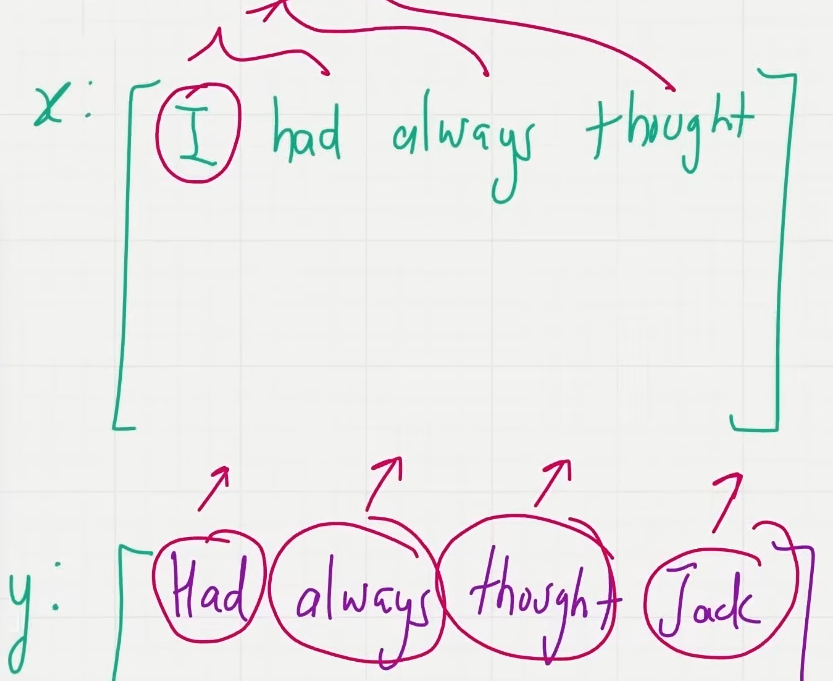

In [33]:

Image("images/stage2_2_LLM_Training_evaluation/input_output_pair.png", width=300)

## Data Loader implementation

In [35]:
from torch.utils.data import Dataset, DataLoader

class GPTDatasetV1(Dataset):
    def __init__(self, text_data, tokenizer, context_length, stride):
        self.input_ids = []
        self.target_ids = []

        # tokenize the entire text data
        token_ids = tokenizer.encode(text_data, allowed_special={"|<endoftext>|"})

        # use a sliding window to chunk the book into overlapping sequence of max length context_length
        for i in range(0, len(token_ids) - context_length, stride):
            input_chunk = token_ids[i:i + context_length]
            target_chunk = token_ids[i + 1:i + context_length + 1]

            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]
    

# use the dataset class to create a dataset and dataloader for the text data

def create_dataloader_v1(text_data, batch_size=4, context_length=256, stride=128, shuffle=True, drop_last=True, num_workers=0):
    # initialize the tokenizer
    tokenizer = tiktoken.get_encoding("gpt2")

    # create the dataset
    dataset = GPTDatasetV1(text_data, tokenizer, context_length, stride)

    # create the dataloader
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, drop_last=drop_last, num_workers=num_workers)


    return dataloader

In [36]:
train_ratio = 0.9
split_index = int(len(text_data) * train_ratio)
train_data = text_data[:split_index]
val_data = text_data[split_index:]

torch.manual_seed(123)  # For reproducibility


# create dataloaders for training and validation data
train_dataloader = create_dataloader_v1(train_data, batch_size=2, context_length=GPT_CONFIG_124M["context_length"], 
                                        stride=GPT_CONFIG_124M["context_length"],
                                        shuffle=True, drop_last=True, num_workers=0)

validation_dataloader = create_dataloader_v1(val_data, batch_size=2, context_length=GPT_CONFIG_124M["context_length"],
                                            stride=GPT_CONFIG_124M["context_length"],
                                            shuffle=False, drop_last=True, num_workers=0)

In [39]:
# sanity check

if total_tokens * train_ratio < GPT_CONFIG_124M["context_length"]:
    print("Not enough tokens for the training dataloader"
    "Try to lower the GPT_CONFIG_124M['context_length'] or increase training_ratio.")
else:
    print(f"Training dataloader created with {len(train_dataloader)} batches of size {train_dataloader.batch_size}.")

if total_tokens * (1 - train_ratio) < GPT_CONFIG_124M["context_length"]:
    print("Not enough tokens for the validation dataloader"
    "Try to lower the GPT_CONFIG_124M['context_length'] or increase training_ratio.")
else:
    print(f"Validation dataloader created with {len(validation_dataloader)} batches of size {validation_dataloader.batch_size}.")

Training dataloader created with 9 batches of size 2.
Validation dataloader created with 1 batches of size 2.


In [43]:
print("Train Loader")
for x,y in train_dataloader:
    print(x.shape, y.shape)
    

print()
print("Validation Loader")
for x,y in validation_dataloader:
    print(x.shape, y.shape)

Train Loader
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])

Validation Loader
torch.Size([2, 256]) torch.Size([2, 256])


In [44]:
train_tokens = 0
for input_batch, target_batch in train_dataloader:
    train_tokens += input_batch.numel()  # numel() gives the total number of elements in the tensor

val_tokens = 0
for input_batch, target_batch in validation_dataloader:
    val_tokens += input_batch.numel()  # numel() gives the total number of elements in the tensor

print("Training tokens: ", train_tokens)
print("Validation tokens: ", val_tokens)
print("Total tokens: ", train_tokens + val_tokens)

Training tokens:  4608
Validation tokens:  512
Total tokens:  5120


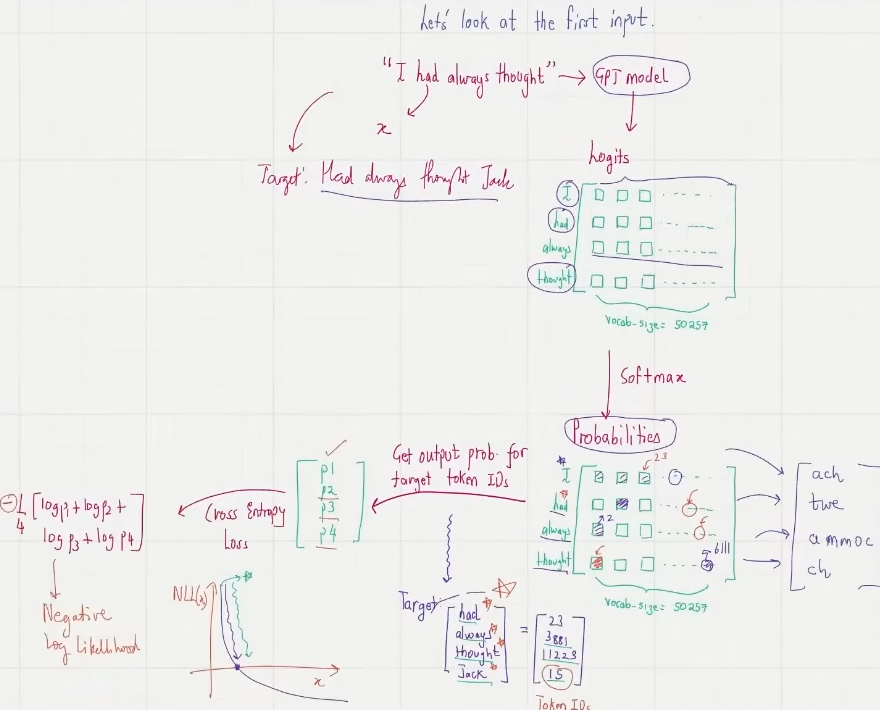

In [45]:
Image("images/stage2_2_LLM_Training_evaluation/tensor_flow_all_stages.png", width=700)


In [46]:
# create GPT model instance

torch.manual_seed(123)  # For reproducibility
model = GPTmodel(GPT_CONFIG_124M)
model.eval()  # Set the model to evaluation mode

GPTmodel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(256, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_value): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=76

- Next, we implement a utility function to calculate the cross-entropy loss of a given batch

- In addition, we implement a second utility function to compute the loss for a user-specified number of batches

In [47]:
def calc_loss_batch(input_batch, target_batch, model, device):

    input_batch = input_batch.to(device)
    target_batch = target_batch.to(device)

    logits = model(input_batch)  # Get logits from the model

    # calculate cross-entropy loss between logits and target_batch
    loss = torch.nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten())

    return loss

# calculate loss of all batches together
def calc_loss_dataloader(data_loader, model, device, num_batches=None):
    total_loss = 0.0
    if len(data_loader) == 0:
        return float('nan')
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))

    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break

    avg_loss = total_loss / num_batches 
    return avg_loss

In [49]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Available device: ", device)

Available device:  cuda


In [50]:
model.to(device)

torch.manual_seed(123)

with torch.no_grad():
    train_loss = calc_loss_dataloader(train_dataloader, model, device)
    val_loss = calc_loss_dataloader(validation_dataloader, model, device)


print("Training loss: ", train_loss)
print("Validation loss", val_loss)

Training loss:  10.974333763122559
Validation loss 10.9493408203125


## Training Loop: Backpropagation to improve (reduce) the Losses

In [51]:
def train_model_simple(model, train_dataloader, validation_dataloader, optimizer, device, num_epochs,
                       eval_freq, eval_iter, start_context, tokenizer):
    
    # intilize list to track losses and seen tokens

    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1

    # main training loop
    for epoch in range(num_epochs):
        model.train() # set model in training mode

        for input_batch, target_batch in train_dataloader:
            optimizer.zero_grad() # reset loss gradients from previous batch iterations
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward() # calculate loss gradients
            optimizer.step() # update model weights using loss gradients
            tokens_seen += input_batch.numel() # get total number of elements (or tokens) in input batch
            global_step += 1

            # evaluation step (optional)
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(model, train_dataloader, validation_dataloader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Epochs {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")


        # print a sample text after each epoch
        generate_and_print_sample(model, tokenizer, device, start_context)

        return train_losses, val_losses, track_tokens_seen

In [55]:
def evaluate_model(model, train_dataloader, validation_dataloader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_dataloader(train_dataloader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_dataloader(validation_dataloader, model, device, num_batches=eval_iter)

    model.train()
    return train_loss, val_loss

- The evaluate_model function calculates the loss over training and vaidateion set while ensuring model is in evaluation mode

In [56]:
def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(model=model,
                                         idx=encoded,
                                         max_new_tokens=50,
                                         context_size=context_size)
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))
    model.train()

In [54]:
GPT_CONFIG_124M

{'vocab_size': 50257,
 'context_length': 256,
 'emb_dim': 768,
 'n_heads': 12,
 'n_layers': 12,
 'drop_rate': 0.1,
 'qkv_bias': True}

In [ ]:
import time
start_time = time.time()

torch.manual_seed(123)
model = GPTmodel(GPT_CONFIG_124M)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)

num_epochs = 10
train_losses, val_losses, tokens_seen = train_model_simple(model, train_dataloader, validation_dataloader,
                                                           optimizer, device, num_epochs=num_epochs,
                                                           eval_freq=5, eval_iter=5,
                                                           start_context="Every effort moves you",
                                                           tokenizer=tokenizer)


end_time = time.time()

execute_time_mins = (end_time - start_time)/60

print(f"Training completed in {execute_time_mins:.2f} minutes")